In [1]:
import BPTK_Py
from BPTK_Py import Model
from BPTK_Py import sd_functions as sd

print(BPTK_Py.__version__)

bptk = BPTK_Py.bptk()

from BPTK_Py import Model
from BPTK_Py import sd_functions as sd
import BPTK_Py.sddsl.functions as sddsl

bptk = BPTK_Py.bptk()

print("BPTK-Py erfolgreich geladen!")

from BPTK_Py import Model
from BPTK_Py import sd_functions as sd
import BPTK_Py
print(BPTK_Py.__version__)
import importlib.metadata

import random  # Importiert das gesamte Modul für random.seed()
from random import randint as rn  # Importiert gezielt randint unter dem Alias r

import BPTK_Py.sddsl.functions as sd


bptk = BPTK_Py.bptk()


#https://www.waldwissen.net/de/technik-und-planung/landschaftsentwicklung/waldausdehnung-im-schweizer-alpenraum
# Im Vormarsch ist der Wald also auf den so genannten Grenzertragslagen.
#Brachlandes
#Kommt der Wald trotzdem unverdrossen zurück? Wirken die finanziellen Anreize zur Aufrechterhaltung der Bewirtschaftung nicht?
#https://www.wsl.ch/de/news/waldbericht-2025-schweizer-wald-unter-anpassungsdruck/

#erster zirkel Landwirtschat->Freie Fläche->Waldwachstum
#zweiter zirkel totholz bildung waldgesundheit and totholz reabsorption
#dirtter zirkel natural desaster anfälligkeit wegen sinkender waldgesundheit?


0.38.4
BPTK-Py erfolgreich geladen!
0.38.4


In [ ]:
%pip install --force-reinstall --no-deps --no-cache-dir Werkzeug==2.2.3



Jahr	Intensivierungsindex \(I\)
1980	0,90
1990	1,10
2000	1,35
2010	1,60
2020	1,85
2026	2,00

Begründung:
- Die Zahl der Landwirtschaftsbetriebe sank von rund 93'000 (1990) auf 47'000 (2024) (−49 %), während sich die durchschnittliche Betriebsgrösse von 11,5 ha auf 22,1 ha nahezu verdoppelte. Das ist ein klarer Indikator für Intensivierung und Strukturwandel.
  OECD+1
- Auch in Voralpen- und Alpenregionen zeigen Agroscope-Studien zwischen 2000 und 2020 eine stärkere Spezialisierung und innere Aufstockung der Betriebe.
  agroscope.admin.ch
Falls du jährliche Werte brauchst, kannst du zwischen den Stützpunkten linear interpolieren.
2. Einfluss auf die Aufgabe von Agrarflächen in den Alpen
Hier ist der Zusammenhang wichtig: Die Intensivierung führt nicht direkt zur Wiederbewaldung, sondern zur räumlichen Konzentration der Landwirtschaft.

Der Mechanismus lautet:
1. produktive Tal- und Hanglagen werden stärker mechanisiert und intensiviert,
2. steile, schwer erreichbare Flächen werden wirtschaftlich unattraktiv,
3. diese Flächen werden aufgegeben,
4. zunächst entstehen Gebüsch und Strauchvegetation,
5. später setzt natürliche Wiederbewaldung ein.
   bafu.admin.ch+1
Geschätzter Zusammenhang für dein Modell
Ich würde die jährliche Aufgabequote der alpinen Nutzfläche an den Intensivierungsindex koppeln.


Umwandlung in Wald und Gehölze

Rund 30 % der Landwirtschaftsflächen, die zwischen 1985 und 2018 ihre Nutzung verloren, wurden zu Wald oder Gehölzen. Besonders betroffen waren Alpweiden.
swissstats.bfs.admin.ch

In [2]:

#growth = model.flow("growth")

In [10]:
#Klimate severity to acid_deposition und drought_heat

#Waldflächenverlust: Eine Waldfläche wird dauerhaft einer anderen Nutzung zugeführt. Das gehört in die Waldflächenbilanz. Waldschäden und Mortalität:

model = Model(    starttime=1980,
    stoptime=2026,
    dt=1.0,
    name="SwissForest")

##Parameters
rs=0.01
r0=0.002
alpha=0.3

#stock Ein Stock repräsentiert den aktuellen Zustand des Systems Ein Stock repräsentiert den aktuellen Zustand des Syste
forest_area = model.stock("forest_area")
forest_health = model.stock("forest_health")
wald_verlust = model.stock("wald_verlust")
deadwood=model.stock("deadwood")
#agrar
#intensity_agrar = model.stock("intensity_agrar")
Agrarfläche=model.stock("agrar")
#space
freespace=model.stock("freespace")
#climate
#swiss_climate = model.stock("swiss_climate")

#initial vars
#forrest
forest_area.initial_value=1.15#millionen hektar
forest_health.initial_value=1.0
wald_verlust.initial_value = 0.0
#agrar
#intensity_agrar.initial_value=0.9
freespace.initial_value = 0.122
Agrarfläche.initial_value=4.129100*0.35#originally round 35% of swissagrar area is in the mountenous area in which most of the growth happened

#Region (Alpensüdseite mit einem Waldanteil von knapp 55 %. Jura mit 40 %,  Voralpen mit 35 % und die Alpen mit 28 %.  Mittelland 24%)
#externe Zeitreihen
climate_data = model.converter("climate_data")
agrar_data = model.converter("agrar_data")



#flow
natural_growth = model.flow("_ngrowth")#freespace → forest_area
wiederaufforstung=model.flow("_wiederaufforstung")#freespace → forest_area
Rodung=model.flow("_rodung")#forest_area → freespace
verlust_durch_n_ereignissse=model.flow("_verlust")
decrease_agrar=model.flow("_decrease_agrar")#Agrarfläche → freespace
damage_from_climate=model.flow("_damage_from_climate")
damage_from_events=model.flow("_damage_from_events")
deadwood_decomposition=model.flow("_deadwood")
deadwood_reabsorption=model.flow("_deadwood_reabsorption")
#climate_severity=model.flow("_climate_severity")

#flow equation /Converter
climate_severity = model.converter("climate_severity")

# Zusätzliche Flows
health_recovery = model.flow("health_recovery")
health_damage = model.flow("health_damage")

climate_data.equation = sd.lookup(sd.time(), "climate_data")
agrar_data.equation = sd.lookup(sd.time(), "agrar_data")

# Vorläufiger Klimabelastungsindex
climate_severity.equation = (
    climate_data) # erst später* sd.random(0, 1))

decrease_agrar.equation = Agrarfläche * (
    r0 * (1 + alpha * (agrar_data - 1)))

natural_growth.equation=freespace*rs*forest_health
wiederaufforstung.equation = 0.0

Rodung.equation = 0.0





#delta wald
delta_wald=natural_growth+wiederaufforstung-Rodung-verlust_durch_n_ereignissse




random.seed(123)

#climate_severity.equation = climate_data * sd.random(0, 1)
#damage_from_climate.equation=climate_severity
#if climate_severity>0.5:

 #   damage_from_events.equation= (climate_severity*rn(0, 1))/forest_health
#else:
 #   damage_from_events.equation=0

damage_from_events.equation = sd.If(climate_severity > 0.5,
    forest_area * 0.002 * climate_severity,0.0)

verlust_durch_n_ereignissse.equation = (damage_from_events)

health_recovery.equation = ( (1.0 - forest_health) * 0.05)

health_damage.equation = ( forest_health * climate_severity * 0.02)

deadwood_decomposition.equation = (    deadwood * 0.05)

deadwood_reabsorption.equation = ( deadwood_decomposition)

# Stock equations
#Agrarfläche.equation = -decrease_agrar
#forest_area.equation = natural_growth
#freespace.equation = ( decrease_agrar- natural_growth)
#deadwood.equation = climate_severity+damage_from_climate
#forest_health.equation = forest_health-damage_from_climate*deadwood


# Waldfläche
#forest_area.inflows = [natural_growth, wiederaufforstung]

#forest_area.outflows = [ Rodung, verlust_durch_n_ereignissse]
forest_area.equation = (
    natural_growth
    + wiederaufforstung
    - Rodung
    - verlust_durch_n_ereignissse#
)

# Landwirtschaft
#Agrarfläche.outflows = [ decrease_agrar]
Agrarfläche.equation = -decrease_agrar

# Freie Fläche
#freespace.inflows = [decrease_agrar,Rodung]

#freespace.outflows = [natural_growth, wiederaufforstung]

freespace.equation = (decrease_agrar
    + Rodung
    - natural_growth
    - wiederaufforstung)

# Waldgesundheit
#forest_health.inflows = [    health_recovery]

#forest_health.outflows = [    health_damage]

forest_health.equation = health_recovery - health_damage

# Totholz
#deadwood.inflows = [
    # Hier später den Totholzeintrag ergänzen]

#deadwood.outflows = [    deadwood_decomposition]

deadwood_formation = model.flow("deadwood_formation")

deadwood_formation.equation = damage_from_events #* biomass_factor

deadwood.equation = (    deadwood_formation - deadwood_decomposition)


# Prüfen, ob die Verknüpfungen tatsächlich am Stock angekommen sind
#print("Forest inflows:", forest_area.inflows)
#print("Forest outflows:", forest_area.outflows)

#print("Health inflows:", forest_health.inflows)
#print("Health outflows:", forest_health.outflows)

#print("Growth equation:", natural_growth.equation)
#print("Health damage equation:", health_damage.equation)

# Lookup-Daten direkt dem Modell geben
model.points["climate_data"] = [
    [1980, 1.7], [1981, 1.72], [1982, 1.68],
    [1983, 1.75], [1985, 1.5], [1990, 1.1],
    [1995, 1.2], [2000, 0.9], [2003, 0.1],
    [2005, 0.8], [2010, 1.1], [2015, 0.6],
    [2020, 0.4], [2025, 0.2], [2026, 2.1]
]

model.points["agrar_data"] = [
    [1980, 0.90], [1990, 1.10], [2000, 1.35],
    [2010, 1.60], [2020, 1.85], [2026, 2.00]
]

# Direkte Simulation ohne Scenario Manager


#print(df_direct)

# Nichtnegative Bestände
forest_area.non_negative = True
Agrarfläche.non_negative = True
freespace.non_negative = True
deadwood.non_negative = True


print("Growth rate:", rs)
print("Growth equation:", natural_growth.equation)
print("Forest equation:", forest_area.equation)
print("Agriculture equation:", Agrarfläche.equation)



#Strukturwandel im Berggebiet: Die Zahl der Bergbetriebe nimmt massiv ab, während die verbleibenden Höfe wachsen. Am Beispiel Graubünden sank die Zahl der Betriebe innerhalb von 30 Jahren (1990–2020) um über 51 %.
#Gesamtflächenverlust Schweiz: Gesamtschweizerisch hat die Landwirtschaftsfläche zwischen 1985 und 2018 um rund 1.097 bis 1.143 km² (ca. 109.700 bis 114.200 Hektar) abgenommen.
#Rückgang der Betriebe: Die Gesamtzahl der landwirtschaftlichen Betriebe ist in den Bergregionen massiv eingebrochen. Am Beispiel des Kantons Graubünden sank die Anzahl der Betriebe zwischen 1990 und 2020 um 51,8 %

Growth rate: 0.01
Growth equation: ((model.memoize('freespace',t)) * (0.01)) * (model.memoize('forest_health',t))
Forest equation: model.memoize('_ngrowth',t)+model.memoize('_wiederaufforstung',t)-model.memoize('_rodung',t)-model.memoize('_verlust',t)
Agriculture equation: (-1) * (model.memoize('_decrease_agrar',t))


2.2.2
<class 'BPTK_Py.bptk.bptk'>
Manager base_points:
{'climate_data': [[1980, 1.7], [1981, 1.72], [1982, 1.68], [1983, 1.75], [1985, 1.5], [1990, 1.1], [1995, 1.2], [2000, 0.9], [2003, 0.1], [2005, 0.8], [2010, 1.1], [2015, 0.6], [2020, 0.4], [2025, 0.2], [2026, 2.1]], 'agrar_data': [[1980, 0.9], [1990, 1.1], [2000, 1.35], [2010, 1.6], [2020, 1.85], [2026, 2.0]]}

Scenario model points:
{'climate_data': [[1980, 1.7], [1981, 1.72], [1982, 1.68], [1983, 1.75], [1985, 1.5], [1990, 1.1], [1995, 1.2], [2000, 0.9], [2003, 0.1], [2005, 0.8], [2010, 1.1], [2015, 0.6], [2020, 0.4], [2025, 0.2], [2026, 2.1]], 'agrar_data': [[1980, 0.9], [1990, 1.1], [2000, 1.35], [2010, 1.6], [2020, 1.85], [2026, 2.0]]}

Climate 1980:
1.7

Climate 1990:
1.1

Agrar 1980:
0.9

Agrar 1990:
1.1
        forest_area  freespace     agrar  _decrease_agrar  _ngrowth  _rodung  _verlust  climate_severity  forest_health  deadwood  health_damage  health_recovery  _deadwood
t                                                 

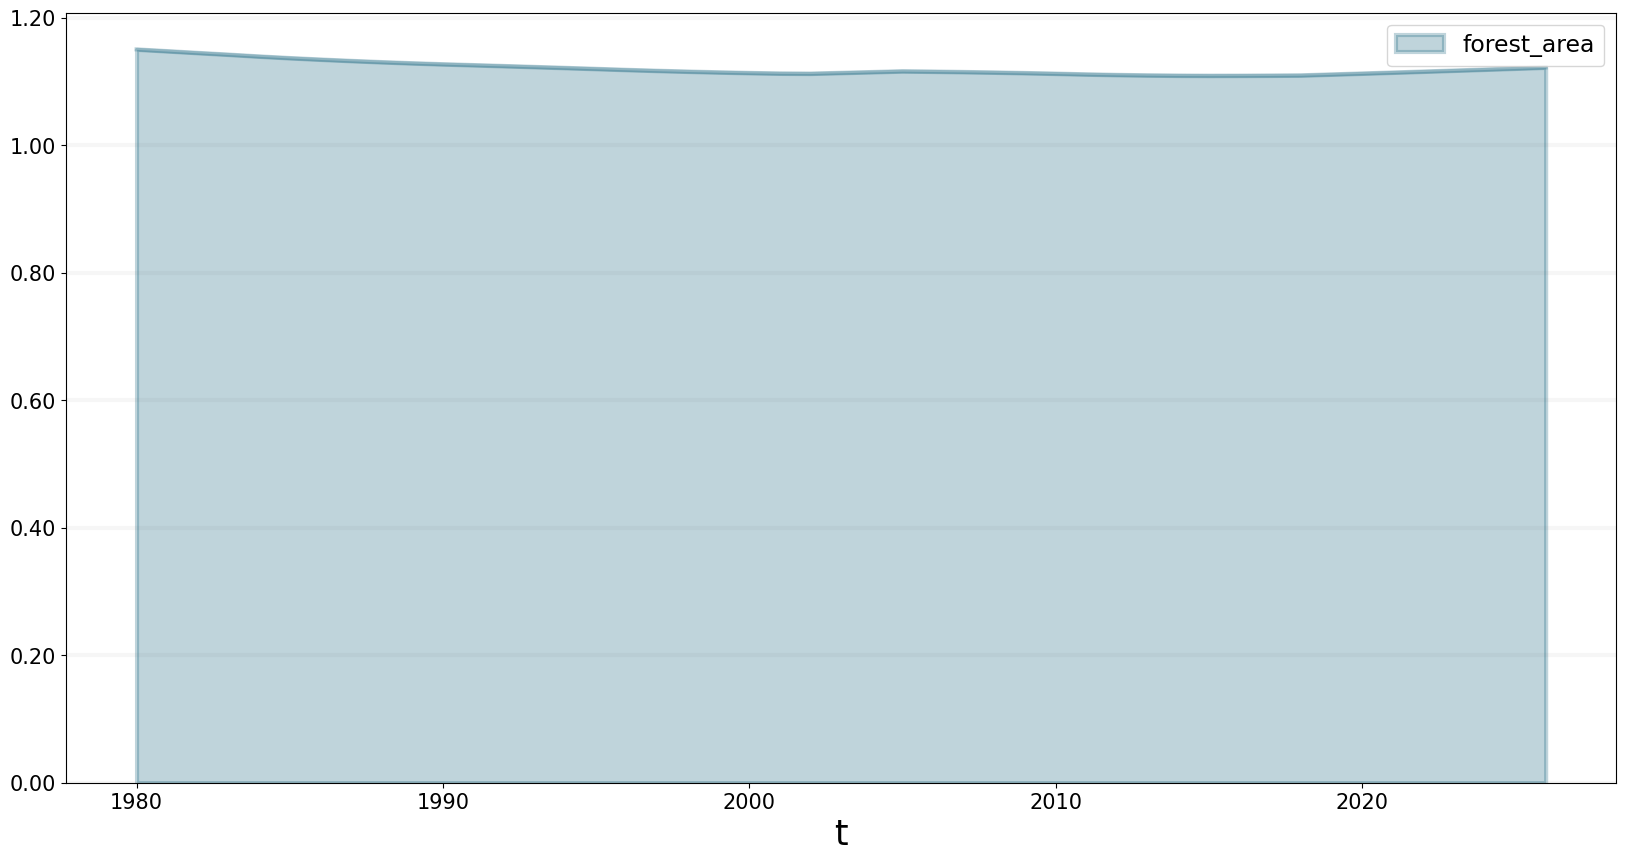

In [13]:
print(importlib.metadata.version("BPTK-Py"))
print(type(bptk))
print(bptk)


# Use a NEW scenario manager name
scenario_manager = {
    "SwissForest_test": {
        "model": model,
        "base_points": {
            "climate_data": [
                [1980, 1.7],
                [1981, 1.72],
                [1982, 1.68],
                [1983, 1.75],
                [1985, 1.5],
                [1990, 1.1],
                [1995, 1.2],
                [2000, 0.9],
                [2003, 0.1],
                [2005, 0.8],
                [2010, 1.1],
                [2015, 0.6],
                [2020, 0.4],
                [2025, 0.2],
                [2026, 2.1]
            ],

            "agrar_data": [
                [1980, 0.90],
                [1990, 1.10],
                [2000, 1.35],
                [2010, 1.60],
                [2020, 1.85],
                [2026, 2.00]
            ]
        }
    }
}

bptk.register_scenario_manager(scenario_manager)
#print("Model points:")
#print(model.points)

#print("Climate points:")
#print(model.points.get("climate_data"))

#print("Agrar points:")
#print(model.points.get("agrar_data"))

#print("Climate 1980:", model._lookup(1980, "climate_data"))
#print("Climate 1990:", model._lookup(1990, "climate_data"))

#print("Agrar 1980:", model._lookup(1980, "agrar_data"))
#print("Agrar 1990:", model._lookup(1990, "agrar_data"))

bptk.register_scenarios(
    scenarios={
        "test": {}
    },
    scenario_manager="SwissForest_test"
)

manager = bptk.scenario_manager_factory.scenario_managers[
    "SwissForest_test"
]

print("Manager base_points:")
print(manager.base_points)

scenario = manager.scenarios["test"]

print("\nScenario model points:")
print(scenario.model.points)

print("\nClimate 1980:")
print(scenario.model._lookup(1980, "climate_data"))

print("\nClimate 1990:")
print(scenario.model._lookup(1990, "climate_data"))

print("\nAgrar 1980:")
print(scenario.model._lookup(1980, "agrar_data"))

print("\nAgrar 1990:")
print(scenario.model._lookup(1990, "agrar_data"))


# Run simulation
results = bptk.run_scenarios(
    scenarios=["test"],
    scenario_managers=["SwissForest_test"],
    equations=[
        "forest_area",
        "freespace",
        "agrar",
        "_decrease_agrar",
        "_ngrowth",
        "_rodung",
        "_verlust",
        "climate_severity",
        "forest_health",
        "deadwood",
        "forest_health",
        "health_damage",
        "health_recovery",
        "deadwood",
        "_deadwood"

    ],
    return_format="df"
)

#print(results)
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.width', 1000)
print(results.iloc[:10])
print(results.iloc[-10:])


print("Module version:", BPTK_Py.__version__)
print("Package version:", importlib.metadata.version("BPTK-Py"))
print("Module location:", BPTK_Py.__file__)
print("Package location:",
      importlib.metadata.distribution("BPTK-Py").locate_file(""))

# Waldfläche simulieren und plotten
bptk.plot_scenarios(scenarios=["test"],
    scenario_managers=["SwissForest_test"],
    equations=["forest_area"])
#free space sollte nich negativ werden, natural growth is wrong, forest_health sollte nicht unkontroliert wachsen

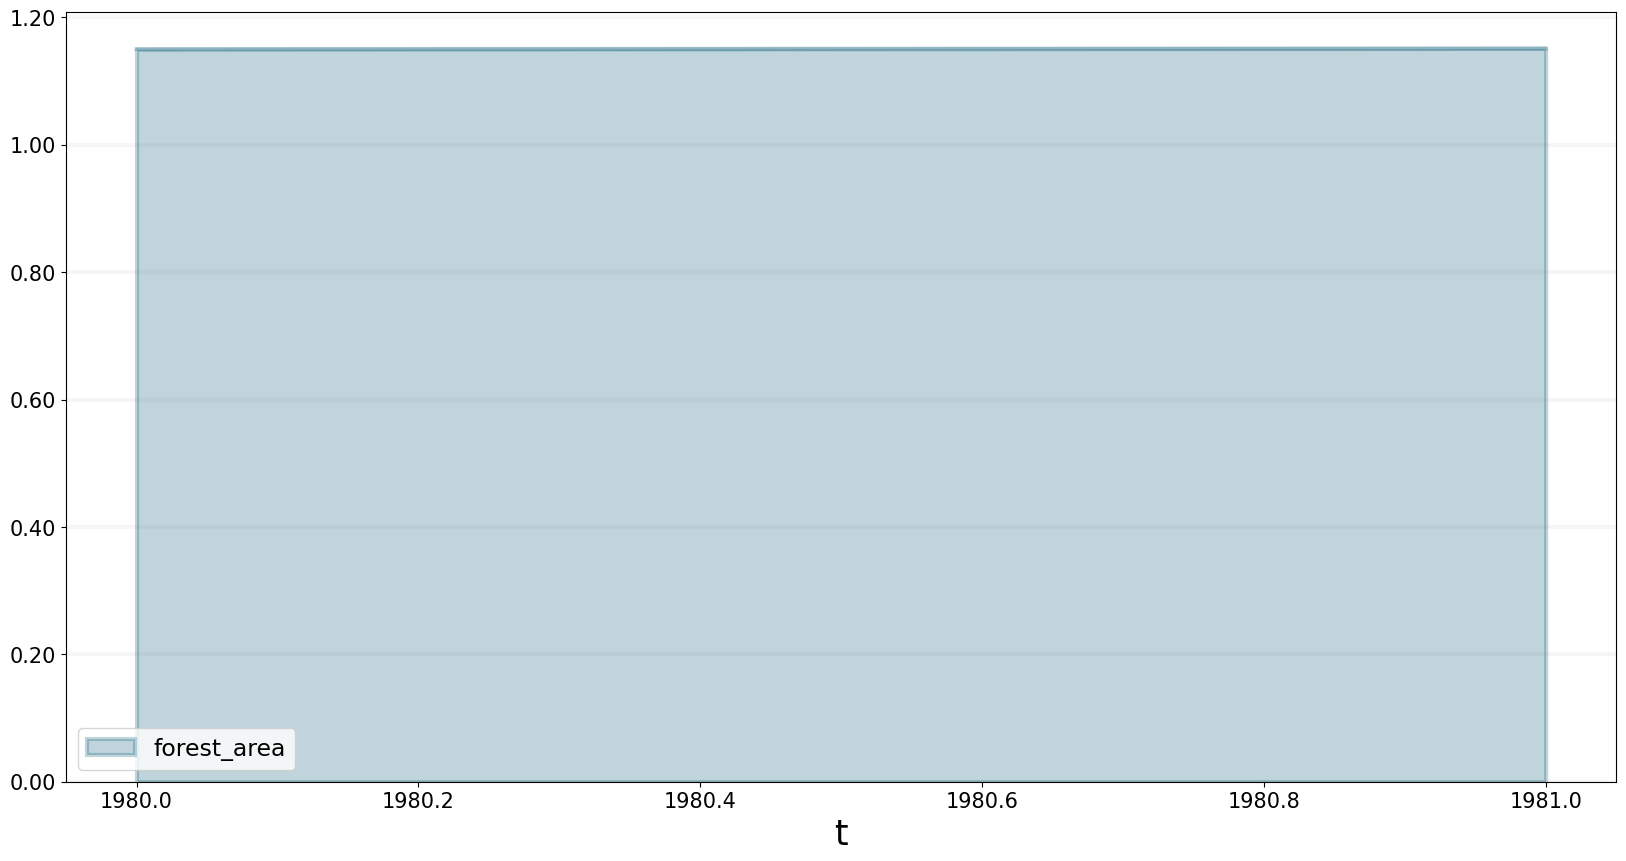

In [8]:
## Beispiel-Flow


# Scenario Manager
scenario_manager = {
    "Forrest2.0": {
        "model": model,
        "base_points": {
            "productivity": [
                [0.0, 0.4],
                [0.25, 0.444],
                [0.5, 0.506],
                [0.75, 0.594],
                [1.0, 1.0],
                [1.25, 1.119],
                [1.5, 1.1625],
                [1.75, 1.2125],
                [2.0, 1.2375],
                [2.25, 1.245],
                [2.5, 1.25]
            ]
        }
    }
}

bptk.register_scenario_manager(scenario_manager)

# Szenario registrieren
bptk.register_scenarios(
    scenarios={
        "Forrest2.0a": {}
    },
    scenario_manager="Forrest2.0"
)

# Waldfläche simulieren und plotten
bptk.plot_scenarios(
    scenarios=["Forrest2.0a"],
    scenario_managers=["Forrest2.0"],
    equations=["forest_area"]
)

In [9]:
import BPTK_Py
import importlib.metadata
import inspect

print("BPTK module:", BPTK_Py.__version__)
print("Package:", importlib.metadata.version("BPTK-Py"))

# Prüfen, welche SD-DSL-Funktionen verfügbar sind
try:
    import BPTK_Py.sddsl.functions as sd

    print("\nVerfügbare Funktionen:")
    for name in [
        "lookup",
        "time",
        "If",
        "random",
        "Random",
        "normal",
        "uniform",
        "montecarlo",
        "pulse"
    ]:
        obj = getattr(sd, name, None)
        print(name, "->", obj)

except Exception as e:
    print("Importproblem:", repr(e))

# Prüfen, welche Methoden dein Model besitzt
print("\nModel-Methoden:")
for name in ["stock", "flow", "converter", "biflow"]:
    print(name, "->", hasattr(Model, name))

BPTK module: 0.38.4
Package: 2.2.2

Verfügbare Funktionen:
lookup -> <function lookup at 0x000002348730ADE0>
time -> <function time at 0x000002348730A660>
If -> <function If at 0x000002348730B420>
random -> <function random at 0x000002348730B2E0>
Random -> <class 'BPTK_Py.sddsl.operators.Random'>
normal -> <function normal at 0x00000234873185E0>
uniform -> <function uniform at 0x000002348730B240>
montecarlo -> <function montecarlo at 0x0000023487318540>
pulse -> <function pulse at 0x000002348730AE80>

Model-Methoden:
stock -> True
flow -> True
converter -> True
biflow -> True


In [20]:
#print(inspect.signature(sd.lookup))
#print(inspect.getsource(sd.lookup))
#print(inspect.getsource(sd.Lookup))

print(inspect.getsource(type(model)._lookup))
print(inspect.signature(type(model)._lookup))

    def _lookup(self,x, points):
        """Define a lookup function.
        
        Function that interpolate between set of points. This is used by the SD DSL lookup function.
        
        Args:
            x: Value.
                x-value to find the y value for
            points: List.
                List of coordinates.
        
        Returns: Float.
            Returns the value that has been looked up.
        """

        #This is used internally by SD DSL lookup function / the Lookup operator.

        if type(points) is str:
            points = self.points[points]


        x_vals = np.array([x[0] for x in points])
        y_vals = np.array([x[1] for x in points])

        if x <= x_vals[0]:
            return y_vals[0]

        if x >= x_vals[len(x_vals) - 1]:
            return y_vals[len(x_vals) - 1]

        f = interp1d(x_vals, y_vals)
        return float(f(x))

(self, x, points)


In [23]:
equations=[
    "agrar",
    "_decrease_agrar",
    "climate_data",
    "agrar_data"
]
for _ in equations:
    print(type(_))

<class 'str'>
<class 'str'>
<class 'str'>
<class 'str'>
